/tmp/ipykernel_1043/999925202.py:7: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(start='2023-01-01', end='2024-12-31', freq='M')


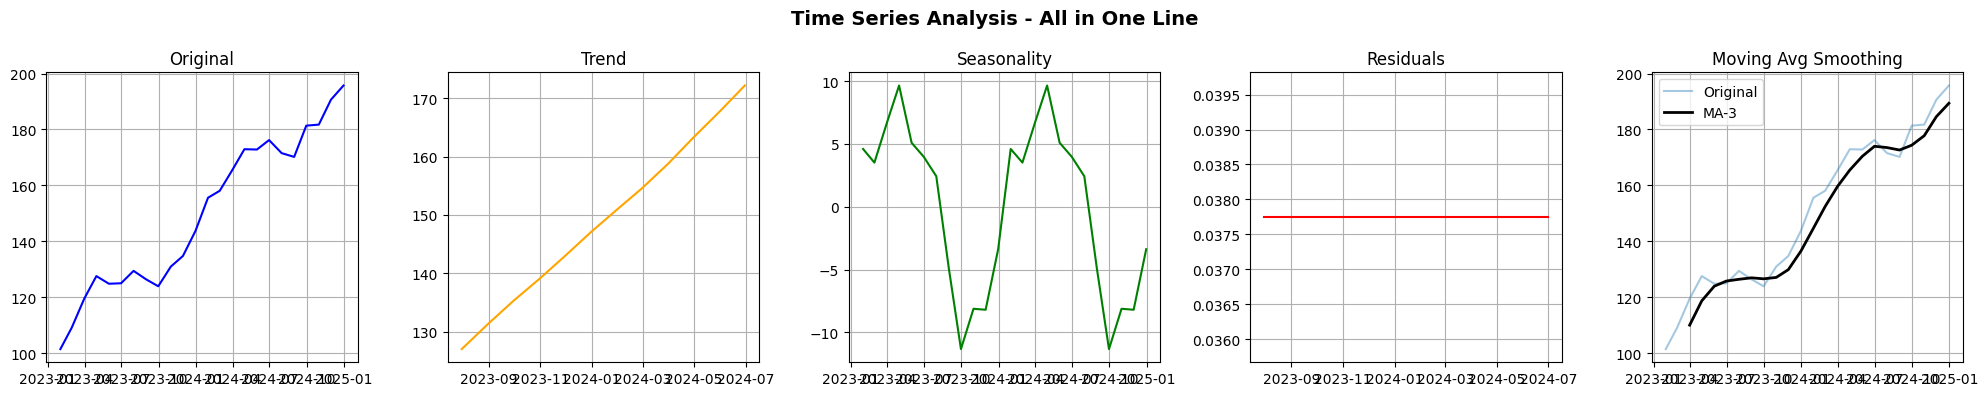

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# 1. Dataset banvu
dates = pd.date_range(start='2023-01-01', end='2024-12-31', freq='M')
np.random.seed(42)
trend = np.linspace(100, 200, len(dates))
seasonality = 10 * np.sin(np.linspace(0, 4*np.pi, len(dates)))
noise = np.random.normal(0, 3, len(dates))
prices = trend + seasonality + noise
df = pd.DataFrame({'Date': dates, 'Price': prices})
df.set_index('Date', inplace=True)

# 2. Decompose ani Moving Average calculate
result = seasonal_decompose(df['Price'], model='additive', period=12)
df['MA_3_Month'] = df['Price'].rolling(window=3).mean()

# 3. EKDACH FIGURE - 1 Line madhe 5 Graphs
fig, axes = plt.subplots(1, 5, figsize=(20, 4))  # 1 row, 5 columns

# Graph 1: Original
axes[0].plot(df['Price'], color='blue')
axes[0].set_title('Original')
axes[0].grid(True)

# Graph 2: Trend
axes[1].plot(result.trend, color='orange')
axes[1].set_title('Trend')
axes[1].grid(True)

# Graph 3: Seasonality
axes[2].plot(result.seasonal, color='green')
axes[2].set_title('Seasonality')
axes[2].grid(True)

# Graph 4: Residuals
axes[3].plot(result.resid, color='red')
axes[3].set_title('Residuals')
axes[3].grid(True)

# Graph 5: Moving Average
axes[4].plot(df['Price'], alpha=0.4, label='Original')
axes[4].plot(df['MA_3_Month'], color='black', linewidth=2, label='MA-3')
axes[4].set_title('Moving Avg Smoothing')
axes[4].legend()
axes[4].grid(True)

plt.suptitle('Time Series Analysis - All in One Line', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()